# 04 · Business Insights & Threshold
**Project 2: Telco Customer Churn Prediction**

## Objective
- Confusion matrix and classification report at the default threshold (0.5) and at a **business threshold**
- Show the top drivers of churn
- Turn the model into business insights: who to contact, and which customer segments churn most
- Test the example claim "month-to-month, short tenure, high charges churn about 3x more" on real data

> **Data:** the Telco Customer Churn sample dataset (7,043 customers). The file is not included in this repo.
> The notebook uses `data/` if it is there, otherwise it downloads a public copy. See `data/README.md`.

> **Rules I set before running (so the test set stays honest):**
> 1. The final model is the tuned XGBoost from notebook 03, trained on the training data only
> 2. The business threshold is chosen on the **training data** (out-of-fold predictions), using cost assumptions I write down first
> 3. Customer segments are searched on the training data and then **checked** on the test set
> 4. The test set is only used to report results, nothing is changed afterwards

## Project setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"
FIG = ROOT / "outputs" / "insights"
FIG.mkdir(parents=True, exist_ok=True)

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from xgboost import XGBClassifier

from churn_models import build_model_pipeline

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})
BLUE, ORANGE, GREEN, GOLD, GREY = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#7F7F7F"
SOURCE = "Source: Telco Customer Churn sample dataset (7,043 customers)."

def add_source(fig, text=SOURCE):
    fig.text(0.01, -0.01, text, fontsize=8.5, color="#555555", ha="left", va="top")

In [3]:
BASE = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

def load_telco():
    for name in ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn.csv"]:
        local = DATA / name
        if local.exists():
            return pd.read_csv(local)
    return pd.read_csv(BASE)

raw = load_telco()
y = (raw["Churn"] == "Yes").astype(int)
X = raw.drop(columns="Churn")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

ratio = round((y_train == 0).sum() / (y_train == 1).sum(), 2)
TUNED = {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 2}     # from notebook 03 (GridSearchCV, training data only)

def make_final():
    model = XGBClassifier(**TUNED, scale_pos_weight=ratio, random_state=42, eval_metric="logloss")
    return build_model_pipeline(model)

final = make_final().fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
y_arr = y_train.to_numpy()
y_test_arr = y_test.to_numpy()
print("Train:", X_train.shape, "| Test:", X_test.shape, "| scale_pos_weight:", ratio)
print("Sanity check, test ROC-AUC:", round(roc_auc_score(y_test, p_test), 3), "(notebook 03 reported 0.846)")

Train: (5634, 20) | Test: (1409, 20) | scale_pos_weight: 2.77
Sanity check, test ROC-AUC: 0.846 (notebook 03 reported 0.846)


## 1. What does a mistake cost? (assumptions, written before any threshold is chosen)

The dataset has no money columns, so these are **illustrative assumptions**. A real team should replace them with its own numbers.

| Assumption | Value | Meaning |
|---|---|---|
| `V` | $800 | value of keeping a customer (about 12 months of a typical bill of about $70) |
| `C` | $50 | cost of one retention offer (a discount or a call), paid for every customer we flag |
| `R` | 30% | share of real churners that an offer actually saves |

So **catching** a real churner is worth `R x V = $240` on average, and **every flag** costs $50.
A flag pays off only if the chance it is a real churner is above `C / (R x V)`, about 21%.

In [4]:
V, C, R = 800, 50, 0.30
gain_per_catch = R * V
print(f"Each caught churner is worth ${gain_per_catch:,.0f} on average. Each offer costs ${C}.")
print(f"Break-even precision: {C / gain_per_catch:.1%} (the overall churn rate is {y_arr.mean():.1%})")

Each caught churner is worth $240 on average. Each offer costs $50.
Break-even precision: 20.8% (the overall churn rate is 26.5%)


## 2. Choose a business threshold using the training data only
Out-of-fold predictions: every training customer is scored by a model that never saw them.
Then I sweep the threshold and compute precision, recall, F1, and the expected **net benefit** (`TP x R x V - flagged x C`).

In [5]:
oof = cross_val_predict(make_final(), X_train, y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
    flag = oof >= t
    tp = int((flag & (y_arr == 1)).sum())
    fp = int((flag & (y_arr == 0)).sum())
    fn = int((~flag & (y_arr == 1)).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    rows.append({"threshold": t, "flagged": tp + fp, "tp": tp, "precision": precision, "recall": recall,
                 "f1": f1, "net_benefit": tp * R * V - (tp + fp) * C})
th = pd.DataFrame(rows).set_index("threshold")

t_biz = float(th["net_benefit"].idxmax())
near = th[th["net_benefit"] >= 0.99 * th["net_benefit"].max()].index
scale = 1000 / len(y_arr)
flag_all = (y_arr.sum() * R * V - len(y_arr) * C) * scale

print(f"Business-optimal threshold (training out-of-fold): {t_biz:.2f}")
print(f"Thresholds within 1% of the best net benefit: {near.min():.2f} to {near.max():.2f}  (a flat curve)")
print(f"Net benefit per 1,000 customers: ${th.loc[t_biz, 'net_benefit'] * scale:,.0f} at {t_biz:.2f}"
      f" | ${th.loc[0.5, 'net_benefit'] * scale:,.0f} at 0.50"
      f" | ${flag_all:,.0f} if we flag everyone | $0 if we flag nobody")

Business-optimal threshold (training out-of-fold): 0.46
Thresholds within 1% of the best net benefit: 0.39 to 0.49  (a flat curve)
Net benefit per 1,000 customers: $31,521 at 0.46 | $31,166 at 0.50 | $13,685 if we flag everyone | $0 if we flag nobody


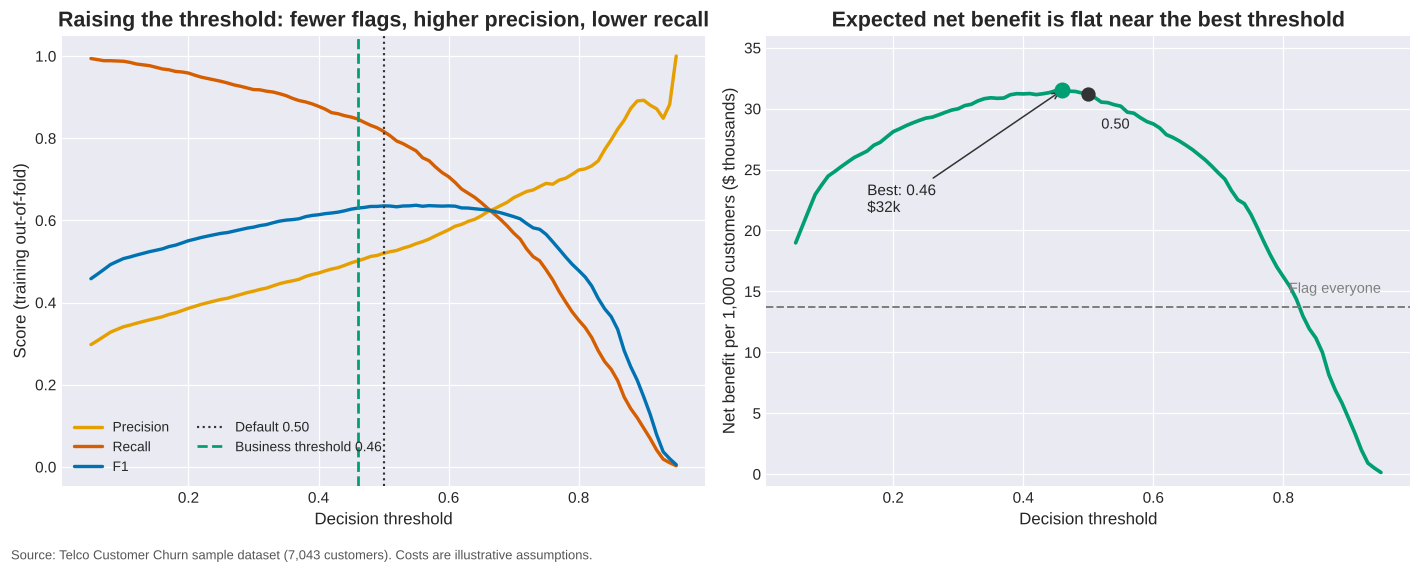

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(th.index, th["precision"], color=GOLD, linewidth=2.2, label="Precision")
ax[0].plot(th.index, th["recall"], color=ORANGE, linewidth=2.2, label="Recall")
ax[0].plot(th.index, th["f1"], color=BLUE, linewidth=2.2, label="F1")
ax[0].axvline(0.5, color="#333333", linestyle=":", linewidth=1.4, label="Default 0.50")
ax[0].axvline(t_biz, color=GREEN, linestyle="--", linewidth=1.8, label=f"Business threshold {t_biz:.2f}")
ax[0].set_title("Raising the threshold: fewer flags, higher precision, lower recall")
ax[0].set_xlabel("Decision threshold")
ax[0].set_ylabel("Score (training out-of-fold)")
ax[0].legend(loc="lower left", ncol=2, fontsize=9)

net = th["net_benefit"] * scale / 1000
ax[1].plot(th.index, net, color=GREEN, linewidth=2.4)
ax[1].axhline(flag_all / 1000, color=GREY, linestyle="--", linewidth=1.3)
ax[1].text(0.95, flag_all / 1000 + 1.2, "Flag everyone", ha="right", color=GREY, fontsize=9.5)
ax[1].scatter([t_biz], [net.loc[t_biz]], s=90, color=GREEN, zorder=5)
ax[1].annotate(f"Best: {t_biz:.2f}\n${net.loc[t_biz]:,.0f}k", xy=(t_biz, net.loc[t_biz]),
               xytext=(t_biz - 0.30, net.loc[t_biz] - 10), fontsize=10, arrowprops=dict(arrowstyle="->", color="#333333"))
ax[1].scatter([0.5], [net.loc[0.5]], s=70, color="#333333", zorder=5)
ax[1].text(0.52, net.loc[0.5] - 2.8, "0.50", fontsize=9.5)
ax[1].set_ylim(-1, 36)
ax[1].set_title("Expected net benefit is flat near the best threshold")
ax[1].set_xlabel("Decision threshold")
ax[1].set_ylabel("Net benefit per 1,000 customers ($ thousands)")
add_source(fig, SOURCE + " Costs are illustrative assumptions.")
plt.tight_layout()
plt.savefig(FIG / "threshold_analysis.png")
plt.show()

**Reading it:** under these assumptions the best threshold is only a little below 0.5, and the curve is **flat** over a wide range,
so the exact value is not fragile. What matters more is the cost ratio, which the next table varies.
The scores are also **not true probabilities**: the class weight (`scale_pos_weight`) inflates them, so a threshold of 0.45 does not mean a 45% chance of churn.

In [7]:
# What if the offer is cheaper or pricier, or works better or worse? (best threshold for each case)
costs, rates = [15, 50, 150], [0.15, 0.30, 0.45]
sens = pd.DataFrame(
    {f"offer works {r:.0%}": [float(th.index[np.argmax(th["tp"] * r * V - th["flagged"] * c)]) for c in costs] for r in rates},
    index=[f"offer costs ${c}" for c in costs])
print("Best threshold under different assumptions (V = $800):")
print(sens.to_string())

Best threshold under different assumptions (V = $800):
                  offer works 15%  offer works 30%  offer works 45%
offer costs $15              0.34             0.10             0.10
offer costs $50              0.68             0.46             0.34
offer costs $150             0.95             0.85             0.68


In [8]:
# Mini challenge: how low must the threshold go to catch a given share of churners?
for target in [0.80, 0.90, 0.95]:
    t = th[th["recall"] >= target].index.max()
    print(f"recall >= {target:.0%}: threshold {t:.2f} | precision {th.loc[t, 'precision']:.2f}"
          f" | flags {th.loc[t, 'flagged'] / len(y_arr):.0%} of customers")

recall >= 80%: threshold 0.51 | precision 0.52 | flags 41% of customers
recall >= 90%: threshold 0.35 | precision 0.45 | flags 53% of customers
recall >= 95%: threshold 0.21 | precision 0.39 | flags 65% of customers


## 3. Confusion matrices on the test set (looked at once)
Both thresholds were fixed on the training data: the default 0.50 and the business threshold.

In [9]:
def report(t):
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_arr, pred).ravel()
    print(f"----- Threshold {t:.2f}: flagged {pred.sum()} of {len(pred)} customers | TN {tn}, FP {fp}, FN {fn}, TP {tp} -----")
    print(classification_report(y_test_arr, pred, target_names=["Stayed", "Churned"], digits=3))
    return pred

pred_default = report(0.50)
pred_biz = report(t_biz)

----- Threshold 0.50: flagged 598 of 1409 customers | TN 741, FP 294, FN 70, TP 304 -----
              precision    recall  f1-score   support

      Stayed      0.914     0.716     0.803      1035
     Churned      0.508     0.813     0.626       374

    accuracy                          0.742      1409
   macro avg      0.711     0.764     0.714      1409
weighted avg      0.806     0.742     0.756      1409

----- Threshold 0.46: flagged 636 of 1409 customers | TN 714, FP 321, FN 59, TP 315 -----
              precision    recall  f1-score   support

      Stayed      0.924     0.690     0.790      1035
     Churned      0.495     0.842     0.624       374

    accuracy                          0.730      1409
   macro avg      0.709     0.766     0.707      1409
weighted avg      0.810     0.730     0.746      1409



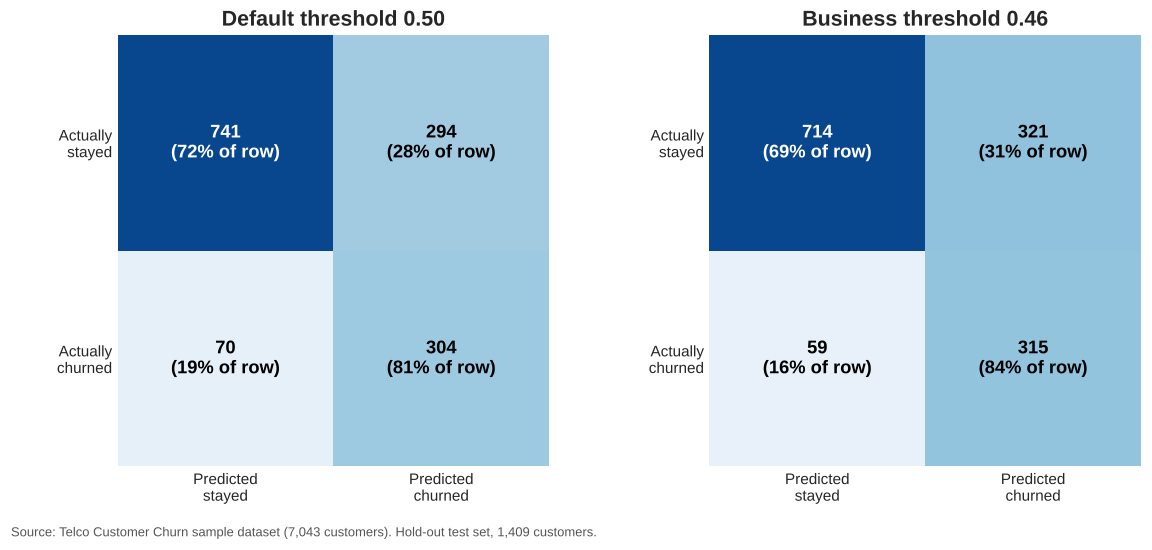

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
for a, pred, t, title in [(ax[0], pred_default, 0.50, "Default threshold 0.50"),
                          (ax[1], pred_biz, t_biz, f"Business threshold {t_biz:.2f}")]:
    cm = confusion_matrix(y_test_arr, pred)
    a.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() * 0.5 else "black", fontsize=12, fontweight="bold")
    a.set_xticks([0, 1])
    a.set_yticks([0, 1])
    a.set_xticklabels(["Predicted\nstayed", "Predicted\nchurned"])
    a.set_yticklabels(["Actually\nstayed", "Actually\nchurned"])
    a.set_title(title)
    a.grid(False)
add_source(fig, SOURCE + " Hold-out test set, 1,409 customers.")
plt.tight_layout()
plt.savefig(FIG / "confusion_matrices.png")
plt.show()

In [11]:
def net_per_1000(pred):
    tp = int(((pred == 1) & (y_test_arr == 1)).sum())
    return (tp * R * V - int(pred.sum()) * C) * 1000 / len(pred)

all_flag = (y_test_arr.sum() * R * V - len(y_test_arr) * C) * 1000 / len(y_test_arr)
print("Net benefit per 1,000 customers on the test set (illustrative assumptions):")
print(f"  flag nobody:                $0")
print(f"  flag everyone:              ${all_flag:,.0f}")
print(f"  model, threshold 0.50:      ${net_per_1000(pred_default):,.0f}")
print(f"  model, threshold {t_biz:.2f}:      ${net_per_1000(pred_biz):,.0f}")

Net benefit per 1,000 customers on the test set (illustrative assumptions):
  flag nobody:                $0
  flag everyone:              $13,705
  model, threshold 0.50:      $30,561
  model, threshold 0.46:      $31,086


## 4. Who should the retention team call first? (cumulative gains)

In [12]:
order = np.argsort(-p_test)
captured = np.cumsum(y_test_arr[order]) / y_test_arr.sum()
share = np.arange(1, len(order) + 1) / len(order)

print(f"Overall churn rate on the test set: {y_test_arr.mean():.1%}")
for q in [0.10, 0.20, 0.30, 0.40]:
    k = int(len(order) * q)
    print(f"Top {q:.0%} ({k}): reach {captured[k - 1]:.1%} of churners",
          f"| group churn rate {y_test_arr[order][:k].mean():.1%}")

Overall churn rate on the test set: 26.5%
Top 10% (140): reach 27.8% of churners | group churn rate 74.3%
Top 20% (281): reach 49.7% of churners | group churn rate 66.2%
Top 30% (422): reach 66.3% of churners | group churn rate 58.8%
Top 40% (563): reach 77.5% of churners | group churn rate 51.5%


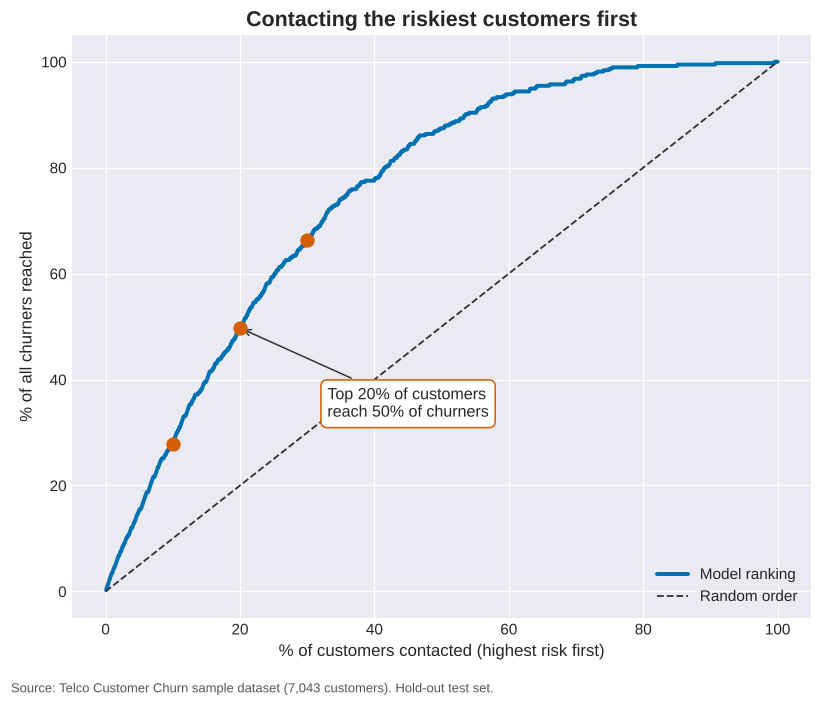

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.plot(share * 100, captured * 100, color=BLUE, linewidth=2.6, label="Model ranking")
ax.plot([0, 100], [0, 100], color="#333333", linestyle="--", linewidth=1.2, label="Random order")
for q in [0.10, 0.20, 0.30]:
    k = int(len(order) * q)
    ax.scatter([q * 100], [captured[k - 1] * 100], s=70, color=ORANGE, zorder=5)
ax.annotate(f"Top 20% of customers\nreach {captured[int(len(order) * 0.2) - 1]:.0%} of churners", xy=(20, captured[int(len(order) * 0.2) - 1] * 100),
            xytext=(33, 33), fontsize=10.5, arrowprops=dict(arrowstyle="->", color="#333333"),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=ORANGE))
ax.set_title("Contacting the riskiest customers first")
ax.set_xlabel("% of customers contacted (highest risk first)")
ax.set_ylabel("% of all churners reached")
ax.legend(loc="lower right")
add_source(fig, SOURCE + " Hold-out test set.")
plt.tight_layout()
plt.savefig(FIG / "gains_chart.png")
plt.show()

## 5. What drives churn?

In [14]:
names = final.named_steps["prep"].get_feature_names_out()
labels = [n.split("__")[1] for n in names]
importance = pd.Series(final.named_steps["model"].feature_importances_, index=labels)

# Direction (does it raise or lower the risk?) from a Logistic Regression on the same features
lr = build_model_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000)).fit(X_train, y_train)
coef = pd.Series(lr.named_steps["model"].coef_[0], index=[n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()])

top = importance.sort_values(ascending=False).head(10)
table = pd.DataFrame({"importance": top.round(3), "effect": np.where(coef[top.index] > 0, "raises risk", "lowers risk")})
print(table.to_string())

                                importance       effect
Contract_Two year                    0.261  lowers risk
Contract_One year                    0.164  lowers risk
InternetService_Fiber optic          0.153  raises risk
PaymentMethod_Electronic check       0.153  raises risk
InternetService_No                   0.070  lowers risk
tenure                               0.040  lowers risk
OnlineSecurity                       0.030  lowers risk
PaperlessBilling                     0.024  raises risk
StreamingMovies                      0.014  raises risk
StreamingTV                          0.013  raises risk


In [15]:
cats = ["MultipleLines", "InternetService", "Contract", "PaymentMethod"]
group = importance.groupby(lambda f: next((c for c in cats if f.startswith(c + "_")), f)).sum().sort_values(ascending=False)
print("Importance grouped by original column (top 5):")
print(group.head(5).round(3).to_string())

Importance grouped by original column (top 5):
Contract           0.425
InternetService    0.223
PaymentMethod      0.155
tenure             0.040
OnlineSecurity     0.030


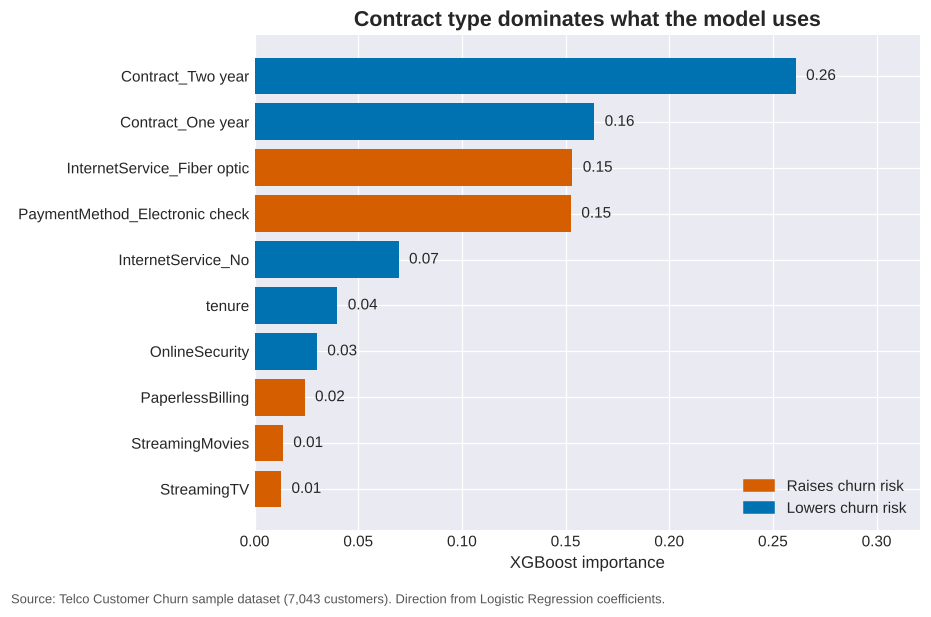

In [16]:
top = importance.sort_values(ascending=False).head(10).iloc[::-1]
colors = [ORANGE if coef[f] > 0 else BLUE for f in top.index]

fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(top.index, top.values, color=colors)
for y_pos, v in enumerate(top.values):
    ax.text(v + 0.005, y_pos, f"{v:.2f}", va="center", fontsize=10)
ax.set_title("Contract type dominates what the model uses")
ax.set_xlabel("XGBoost importance")
ax.set_xlim(0, top.values.max() + 0.06)
ax.legend(handles=[Patch(color=ORANGE, label="Raises churn risk"), Patch(color=BLUE, label="Lowers churn risk")],
          loc="lower right")
add_source(fig, SOURCE + " Direction from Logistic Regression coefficients.")
plt.tight_layout()
plt.savefig(FIG / "churn_drivers.png")
plt.show()

Importance says what the model **uses**, not what **causes** churn. A two-year contract may lower churn because committed customers choose it, not because the contract itself keeps them.

## 6. Customer segments

**The example claim, tested:** "month-to-month, tenure under 6 months, monthly charges over $70 churn about 3x more". Was it true in the training data, and does it hold on the test set?

In [17]:
def example_segment(df):
    return (df["Contract"] == "Month-to-month") & (df["tenure"] < 6) & (df["MonthlyCharges"] > 70)

rows = []
for name, df, target in [("train", X_train, y_train), ("test", X_test, y_test)]:
    m = example_segment(df)
    rows.append({"part": name, "customers": int(m.sum()), "segment churn": target[m].mean(),
                 "overall churn": target.mean(), "lift": target[m].mean() / target.mean()})
print(pd.DataFrame(rows).set_index("part").round(3).to_string())

       customers  segment churn  overall churn   lift
part                                                 
train        410          0.729          0.265  2.748
test         106          0.745          0.265  2.808


**A broader search, checked honestly:** I look for high-churn segments on the **training** data only (every combination of 3 simple factors, at least 100 customers),
then check the same segments on the **test** data. Segments found by searching usually look a bit weaker on new data.

In [18]:
def prepare(df):
    out = pd.DataFrame(index=df.index)
    out["Contract"] = df["Contract"]
    out["InternetService"] = df["InternetService"]
    out["tenure"] = pd.cut(df["tenure"], [-1, 5, 11, 23, 72], labels=["0-5 mo", "6-11 mo", "12-23 mo", "24+ mo"]).astype(str)
    out["charges"] = np.where(df["MonthlyCharges"] > 70, "over $70", "$70 or less")
    out["payment"] = np.where(df["PaymentMethod"] == "Electronic check", "electronic check", "other payment")
    out["TechSupport"] = df["TechSupport"].map({"Yes": "has tech support", "No": "no tech support", "No internet service": "no internet"})
    return out

tr, te = prepare(X_train), prepare(X_test)
tr["churned"] = y_train.to_numpy()
te["churned"] = y_test.to_numpy()

found = []
for combo in combinations(["Contract", "InternetService", "tenure", "charges", "payment", "TechSupport"], 3):
    g = tr.groupby(list(combo))["churned"].agg(["size", "mean"])
    for levels, row in g[g["size"] >= 100].iterrows():
        found.append((dict(zip(combo, levels)), int(row["size"]), row["mean"]))
found.sort(key=lambda r: -r[2])

top5 = []
for cond, n_tr, rate_tr in found:
    if all(set(cond.items()) != set(prev[0].items()) for prev in top5):
        m = np.ones(len(te), dtype=bool)
        for k, v in cond.items():
            m &= (te[k] == v).to_numpy()
        top5.append((cond, n_tr, rate_tr, int(m.sum()), te.loc[m, "churned"].mean()))
    if len(top5) == 5:
        break

print(f"Overall churn rate: train {y_train.mean():.1%} | test {y_test.mean():.1%}")
for cond, n_tr, rate_tr, n_te, rate_te in top5:
    label = " + ".join(f"{v}" for v in cond.values())
    print(f"{label}")
    print(f"    train: {rate_tr:.1%} (n={n_tr}) | test: {rate_te:.1%} (n={n_te})")

Overall churn rate: train 26.5% | test 26.5%
Fiber optic + 0-5 mo + electronic check
    train: 75.4% (n=325) | test: 79.1% (n=86)
Fiber optic + 0-5 mo + no tech support
    train: 75.0% (n=416) | test: 77.4% (n=115)
Month-to-month + Fiber optic + 0-5 mo
    train: 74.6% (n=453) | test: 75.4% (n=122)
0-5 mo + over $70 + no tech support
    train: 74.2% (n=365) | test: 76.0% (n=100)
0-5 mo + over $70 + electronic check
    train: 74.0% (n=292) | test: 77.6% (n=76)


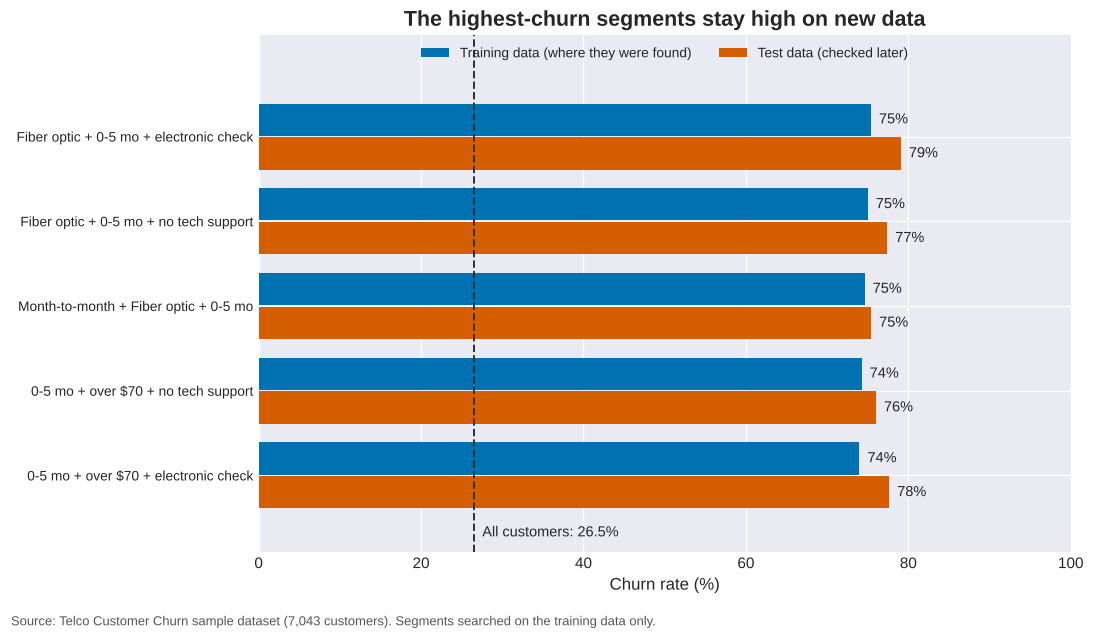

In [19]:
labels = [" + ".join(cond.values()) for cond, *_ in top5][::-1]
tr_rates = [r[2] * 100 for r in top5][::-1]
te_rates = [r[4] * 100 for r in top5][::-1]

fig, ax = plt.subplots(figsize=(10, 5.6))
yy = np.arange(len(labels))
ax.barh(yy + 0.2, tr_rates, 0.38, color=BLUE, label="Training data (where they were found)")
ax.barh(yy - 0.2, te_rates, 0.38, color=ORANGE, label="Test data (checked later)")
for y_pos, a_val, b_val in zip(yy, tr_rates, te_rates):
    ax.text(a_val + 1, y_pos + 0.2, f"{a_val:.0f}%", va="center", fontsize=9.5)
    ax.text(b_val + 1, y_pos - 0.2, f"{b_val:.0f}%", va="center", fontsize=9.5)
base_rate = y_train.mean() * 100
ax.axvline(base_rate, color="#333333", linestyle="--", linewidth=1.3)
ax.text(base_rate + 1, -0.72, f"All customers: {base_rate:.1f}%", fontsize=9.5)
ax.set_yticks(yy)
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(-0.9, len(labels) + 0.2)
ax.set_title("The highest-churn segments stay high on new data")
ax.set_xlabel("Churn rate (%)")
ax.legend(loc="upper center", ncol=2, fontsize=9)
add_source(fig, SOURCE + " Segments searched on the training data only.")
plt.tight_layout()
plt.savefig(FIG / "segments_churn_rate.png")
plt.show()

## Practice Exercise
Which 5 customers in the test set got the highest risk scores? What do they look like?

In [20]:
view = X_test.assign(risk_score=p_test, churned=y_test.to_numpy())
cols = ["customerID", "Contract", "tenure", "MonthlyCharges", "InternetService", "PaymentMethod", "risk_score", "churned"]
print(view.sort_values("risk_score", ascending=False)[cols].head(5).round(2).to_string(index=False))

customerID       Contract  tenure  MonthlyCharges InternetService    PaymentMethod  risk_score  churned
5178-LMXOP Month-to-month       1           95.10     Fiber optic Electronic check        0.95        1
1069-XAIEM Month-to-month       1           85.05     Fiber optic Electronic check        0.95        1
0295-PPHDO Month-to-month       1           95.45     Fiber optic Electronic check        0.94        1
9248-OJYKK Month-to-month       1           76.45     Fiber optic Electronic check        0.94        1
6230-BSUXY Month-to-month       1           85.00     Fiber optic Electronic check        0.94        1


## What I would tell a retention team
These are **associations** from one snapshot of data, so each one should be checked with a small experiment before it is trusted.

1. **Rank, then call.** Use the risk score to rank customers. Calling the riskiest 20% reaches about half of all churners, which is far better than calling at random
2. **Pick the threshold with real costs.** My costs are illustrative. If an offer is cheap (an email), flag more customers. If it is expensive (a big discount), flag fewer. The sensitivity table shows how the threshold moves
3. **Start with the clear segments.** Month-to-month customers, especially new ones paying higher bills on fiber optic and paying by electronic check, churn far more than average
4. **Test a contract offer.** Annual and two-year contracts go with much lower churn. A small A/B test of a "switch to an annual plan" offer would show whether that is cause or just who chooses annual plans
5. **Do not read price as the cause.** Within an internet service type, higher charges went with lower churn (notebook 01), so a blanket price cut is not supported by this data
6. **Watch it over time.** Re-check the model and the threshold on fresh data regularly

## Summary
- The final model (tuned XGBoost) was checked on the test set once, at the default and at a business threshold chosen on the training data
- Under the illustrative costs the best threshold is only slightly below 0.5, and the benefit curve is flat, so the decision is not fragile
- Contacting the riskiest 20% of customers reaches about half of all churners
- Contract type dominates the model, and high-churn segments found on the training data stay high on the test data
- Next: finish the Project 2 README and push the repo to GitHub